In [1]:
# mamba activate squidpy-voyagerpy_v1 
import scanpy as sc
import numpy as np
import os
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib as mpl
from tqdm.auto import tqdm
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import random
import pandas as pd
import voyagerpy as vp
import geopandas as gpd
import libpysal as lps
from collections import OrderedDict
import scipy.sparse as sp
import pickle
from scipy.sparse import csr_matrix

import alphashape as alphashape
from shapely.geometry import Point
import geopandas as gpd
from scipy import ndimage as ndi

import pickle

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
# -----------------------------
# helper function
# -----------------------------
def add_cluster_from_pickle(andata, pkl_file, new_col, match_col="cell_id"):
    """
    Add clustering results from a pickle dictionary to andata.obs.

    The pickle file should contain:
        key   = original obs name
        value = cluster label
    """

    with open(pkl_file, "rb") as f:
        cluster_dict = pickle.load(f)

    # make sure dictionary keys are strings
    cluster_dict = {str(k): str(v) for k, v in cluster_dict.items()}

    # map cluster labels into AnnData
    andata.obs[new_col] = andata.obs[match_col].map(cluster_dict)

    # report mapping quality
    n_total = andata.n_obs
    n_missing = andata.obs[new_col].isna().sum()

    print(f"{new_col}")
    print(f"  total cells:   {n_total}")
    print(f"  matched cells: {n_total - n_missing}")
    print(f"  missing cells: {n_missing}")

    # convert to category for plotting
    andata.obs[new_col] = andata.obs[new_col].astype("category")

    return andata


In [3]:
pathout = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
pathdict = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res07'

andata = sc.read_h5ad(os.path.join(pathout, "adata_nb_processed.h5ad"))

In [4]:
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res_07_ratio1p5'
andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r13.pkl"),
    "stlieden_ratio1p5_r13",match_col='cell_id'
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r8.pkl"),
    "stlieden_ratio1p5_r8",match_col='cell_id'
)

stlieden_ratio1p5_r13
  total cells:   669261
  matched cells: 669261
  missing cells: 0
stlieden_ratio1p5_r8
  total cells:   669261
  matched cells: 669261
  missing cells: 0


In [5]:
andata

AnnData object with n_obs × n_vars = 669261 × 5006
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'sample_lab', 'mouse_id', 'Condition', 'Type', 'punch_id', 'n_genes_by_counts', 'cluster_30neig_r07', 'stlieden_ratio1p5_r13', 'stlieden_ratio1p5_r8'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'mean', 'std'
    uns: '30neig', 'Condition_colors', 'Type_colors', 'cluster_30neig_r07', 'log1p', 'mouse_id_colors', 'pca', 'punch_id_colors', 'sample_lab_colors', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'log', 'raw_counts'
    obsp: '30neig_connectivities', '30neig_distances'

In [6]:
andata_subsample = sc.pp.subsample(andata, fraction = 0.4, random_state=1980,copy = True)

In [10]:
andata_subsample.obs["cell_type_num"] = andata_subsample.obs["stlieden_ratio1p5_r13"].copy()

In [11]:
len(andata_subsample.obs["cell_type_num"].cat.codes.unique())

13

In [12]:
cluster_col = "cell_type_num"
cluster_order = [str(i) for i in range(len(andata_subsample.obs["cell_type_num"].cat.codes.unique()))]

andata_subsample.obs[cluster_col] = andata_subsample.obs[cluster_col].astype(str)
andata_subsample.obs[cluster_col] = pd.Categorical(
    andata_subsample.obs[cluster_col],
    categories=cluster_order,
    ordered=True,
)

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


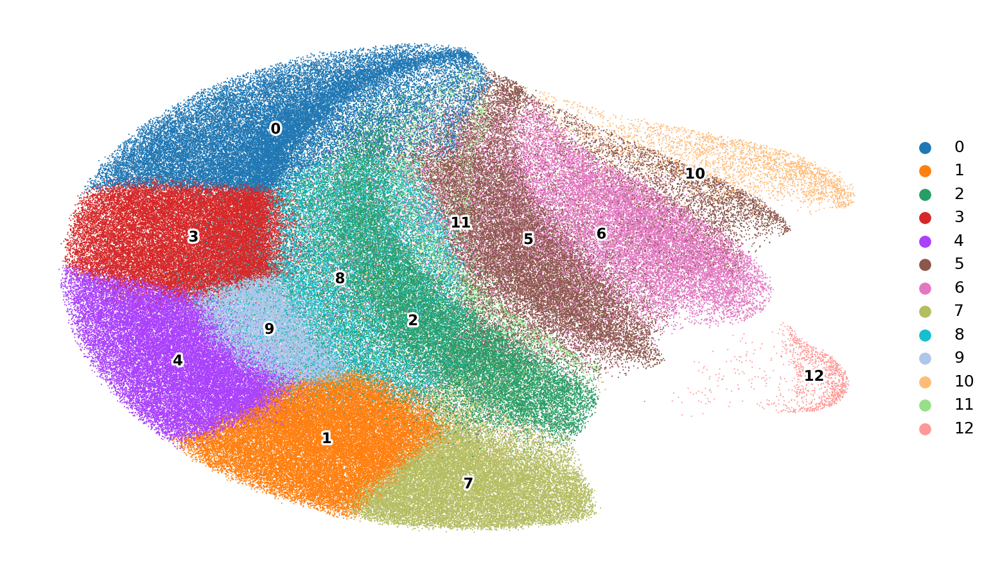

In [13]:
import matplotlib.patheffects as pe
import textwrap
from matplotlib.lines import Line2D

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100
plt.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=300)

legend_loc = "right margin"

ax_out = sc.pl.embedding(
    andata_subsample,
    basis="X_umap",
    color="cell_type_num",
    legend_loc=legend_loc,
    frameon=False,
    size=1,
    edgecolors="black",
    linewidths=0.15,
    show=False,
    ax=ax,
)

ax_out.set_title("", fontsize=6)

X = andata_subsample.obsm["X_umap"]
df = pd.DataFrame(X, columns=["x", "y"], index=andata_subsample.obs_names)
df["lab"] = andata_subsample.obs["cell_type_num"].astype(str).values
centers = df.groupby("lab")[["x", "y"]].median()

label_fs = 5.5
outline_lw = 1.6

for lab, (x, y) in centers.iterrows():
    num = lab.split(":")[0].strip()
    t = ax.text(x, y, num, ha="center", va="center",
                fontsize=label_fs, weight="bold")
    t.set_path_effects([pe.withStroke(linewidth=outline_lw, foreground="white")])


plt.tight_layout()

plt.show()

In [24]:
condition_palette = {
    "Mock": "#E41A1C",  # red
    "CAR":  "#377EB8",  # blue
    "IL15": "#4DAF4A",  # green
    "IL21": "#984EA3",  # purple
    "both": "#FF7F00",  # orange
}

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


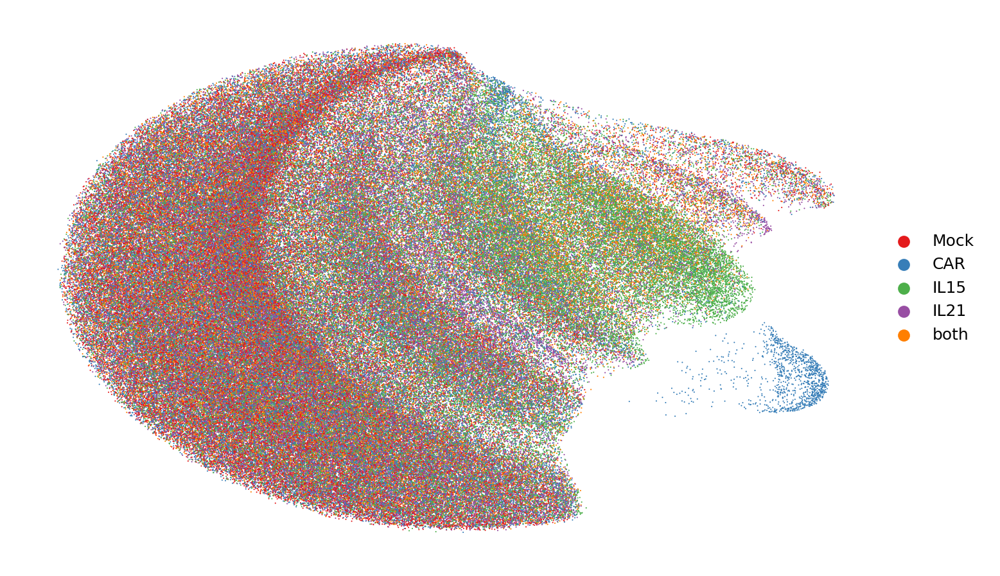

In [25]:
import matplotlib.patheffects as pe
import textwrap
from matplotlib.lines import Line2D

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100
plt.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=300)

legend_loc = "right margin"

ax_out = sc.pl.embedding(
    andata_subsample,
    basis="X_umap",
    color="Condition",
    legend_loc=legend_loc,
    palette=condition_palette,
    frameon=False,
    size=1,
    edgecolors="black",
    linewidths=0.15,
    show=False,
    ax=ax,
)

ax_out.set_title("", fontsize=6)

X = andata_subsample.obsm["X_umap"]
df = pd.DataFrame(X, columns=["x", "y"], index=andata_subsample.obs_names)
df["lab"] = andata_subsample.obs["cell_type_num"].astype(str).values
centers = df.groupby("lab")[["x", "y"]].median()

label_fs = 5.5
outline_lw = 1.6

plt.tight_layout()

plt.show()

In [42]:
andata_subsample.obs['Type']

144469    Metastasis
636818    Metastasis
85281        Primary
254420    Metastasis
537748       Primary
             ...    
350641       Primary
207004    Metastasis
212742       Primary
576582       Primary
634726    Metastasis
Name: Type, Length: 267704, dtype: category
Categories (2, object): ['Primary' < 'Metastasis']

In [45]:
condition_palette = {
    "Primary": "#E41A1C",  # red
    "Metastasis": "#4DAF4A",  # green
   
}

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


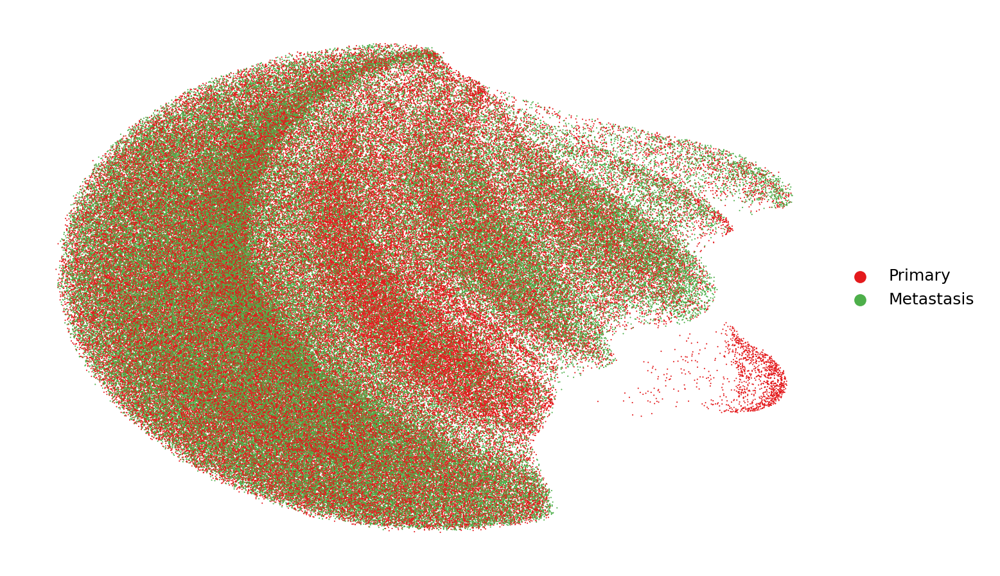

In [46]:
import matplotlib.patheffects as pe
import textwrap
from matplotlib.lines import Line2D

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100
plt.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=300)

legend_loc = "right margin"

ax_out = sc.pl.embedding(
    andata_subsample,
    basis="X_umap",
    color="Type",
    legend_loc=legend_loc,
    palette=condition_palette,
    frameon=False,
    size=1,
    edgecolors="black",
    linewidths=0.15,
    show=False,
    ax=ax,
)

ax_out.set_title("", fontsize=6)

plt.tight_layout()

plt.show()

In [23]:
andata.obs['Condition']

6         IL15
7         IL15
9         IL15
17        IL15
19        IL15
          ... 
688892     CAR
688896     CAR
688900     CAR
688902     CAR
688903     CAR
Name: Condition, Length: 669261, dtype: category
Categories (5, object): ['Mock' < 'CAR' < 'IL15' < 'IL21' < 'both']

In [33]:
andata_il15 = andata[andata.obs['Condition'].isin(['IL15'])].copy()

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


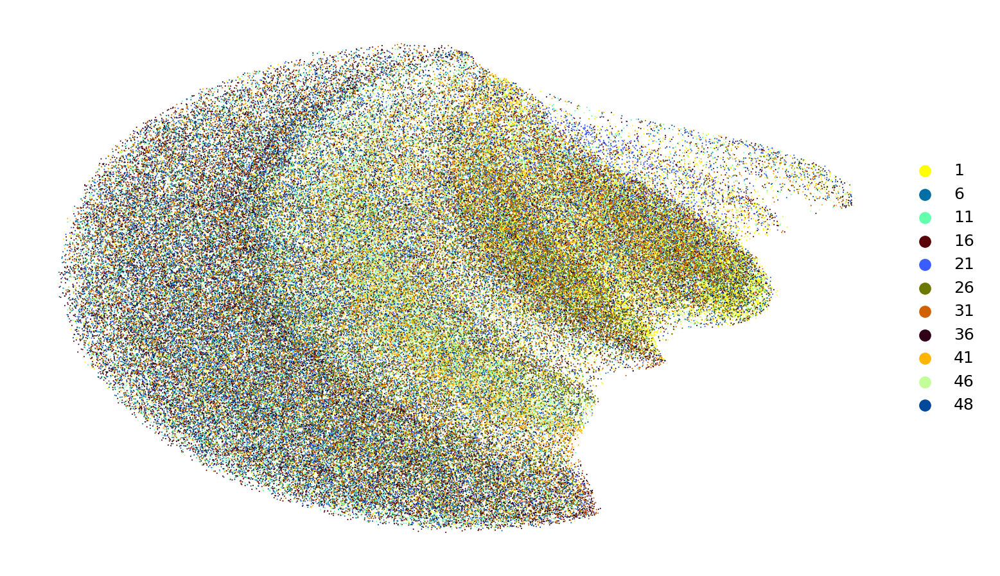

In [34]:
import matplotlib.patheffects as pe
import textwrap
from matplotlib.lines import Line2D

plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 100
plt.rcParams.update({
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(figsize=(5.2, 3.0), dpi=300)

legend_loc = "right margin"

ax_out = sc.pl.embedding(
    andata_il15,
    basis="X_umap",
    color="punch_id",
    legend_loc=legend_loc,
    frameon=False,
    size=1,
    edgecolors="black",
    linewidths=0.15,
    show=False,
    ax=ax,
)

ax_out.set_title("", fontsize=6)


plt.tight_layout()

plt.show()

In [ ]:
coords = np.asarray(andata_subsample.obsm[''])

In [35]:
andata_subsample.obs['Condition']

144469    IL15
636818    IL15
85281     both
254420     CAR
537748    Mock
          ... 
350641    IL15
207004    IL21
212742    IL15
576582    Mock
634726    IL15
Name: Condition, Length: 267704, dtype: category
Categories (5, object): ['Mock' < 'CAR' < 'IL15' < 'IL21' < 'both']

/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(
/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/vf/users/kanferg/conda_v1/envs/squidpy-voyagerpy_v1/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


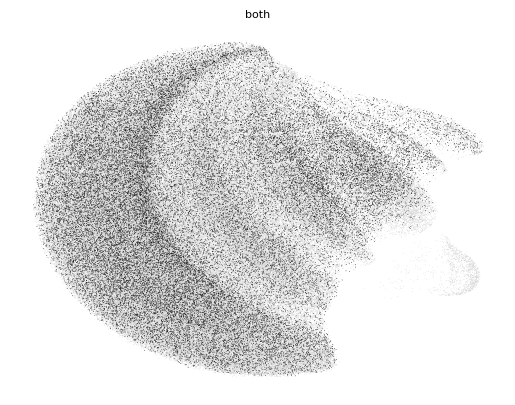

In [40]:
colname = 'both'
ax = sc.pl.umap(andata_subsample, palette = 'lightgrey', show = False,size = 1,wspace=0.5,frameon=False)
sc.pl.umap(andata_subsample[andata_subsample.obs['Condition'] == colname], color = ['cluster_30neig_r07'], ax = ax, legend_loc = None, palette = 'k',size = 1,wspace=0.5,frameon=False,title = colname)

In [1]:
# mamba activate spatiocore_spatial_env
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
# from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
from napari.utils.colormaps import Colormap
from napari_spatialdata import Interactive
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import pickle

from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine
)

In [2]:
# -----------------------------
# helper function
# -----------------------------
def add_cluster_from_pickle(andata, pkl_file, new_col, match_col="cell_id"):
    """
    Add clustering results from a pickle dictionary to andata.obs.

    The pickle file should contain:
        key   = original obs name
        value = cluster label
    """

    with open(pkl_file, "rb") as f:
        cluster_dict = pickle.load(f)

    # make sure dictionary keys are strings
    cluster_dict = {str(k): str(v) for k, v in cluster_dict.items()}

    # map cluster labels into AnnData
    andata.obs[new_col] = andata.obs[match_col].map(cluster_dict)

    # report mapping quality
    n_total = andata.n_obs
    n_missing = andata.obs[new_col].isna().sum()

    print(f"{new_col}")
    print(f"  total cells:   {n_total}")
    print(f"  matched cells: {n_total - n_missing}")
    print(f"  missing cells: {n_missing}")

    # convert to category for plotting
    andata.obs[new_col] = andata.obs[new_col].astype("category")

    return andata


In [3]:
pathout = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
pathdict = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res07'

andata = sc.read_h5ad(os.path.join(pathout, "adata_nb_processed.h5ad"))

In [4]:
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/res_07_ratio1p5'
andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r13.pkl"),
    "stlieden_ratio1p5_r13",match_col='cell_id'
)

andata = add_cluster_from_pickle(
    andata,
    os.path.join(pkl_dir, "stlieden_ratio1p5_r8.pkl"),
    "stlieden_ratio1p5_r8",match_col='cell_id'
)

stlieden_ratio1p5_r13
  total cells:   669261
  matched cells: 669261
  missing cells: 0
stlieden_ratio1p5_r8
  total cells:   669261
  matched cells: 669261
  missing cells: 0


In [7]:
andata.obs["stlieden_ratio1p5_r8"] = andata.obs["stlieden_ratio1p5_r8"].astype(str)
andata.obs["stlieden_ratio1p5_r13"] = andata.obs["stlieden_ratio1p5_r13"].astype(str)



map_spatialleiden_r8 = dict(zip(andata.obs['cell_id'], andata.obs["stlieden_ratio1p5_r8"]))
map_spatialleiden_r13 = dict(zip(andata.obs['cell_id'], andata.obs["stlieden_ratio1p5_r13"]))


In [8]:
path_zarr = '/data/HiTIF/data/spatialomics/neuroblastoma/data/SCAF4480/PrimaryAnalysisOutput/SCAF4480_PA_xenium/nb_orig_label_v1.zarr'
sdata = sd.read_zarr(path_zarr)

/tmp/ipykernel_2369272/1456852835.py:2: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(path_zarr)
no parent found for <ome_zarr.reader.Label object at 0x1554a5cf4510>: None
no parent found for <ome_zarr.reader.Label object at 0x1554a50405d0>: None


In [14]:
class PunchPlotter:
    def __init__(self, sdata,element_name):
        self.sdata = sdata
        self.element_name = element_name
        self.sdata_crop = self.crop_sdata()
        
    def crop_sdata(self):
        extent = sd.get_extent(
            self.sdata[self.element_name],
            coordinate_system="global",
            exact=True,
        )

        xmin, xmax = extent["x"]
        ymin, ymax = extent["y"]

        sdata_cropped = self.sdata.query.bounding_box(
            min_coordinate=[xmin, ymin],
            max_coordinate=[xmax, ymax],
            axes=("x", "y"),
            target_coordinate_system="global",
        )
        return sdata_cropped

    def plot_punch(self, colname, colname_map, palette=None, dpi=100):
        self.sdata_crop["table"].obs[colname] = self.sdata_crop["table"].obs["cell_id"].map(colname_map)
        self.sdata_crop["table"].obs[colname] = self.sdata_crop["table"].obs[colname].astype("category")

        return (
            self.sdata_crop.pl
            .render_labels("cell_labels", color=colname, palette=palette)
            .pl.show(
                coordinate_systems="global",
                figsize=(10, 10),
                dpi=dpi,
                na_in_legend=False,
            )
        )
    
    # def plot_punch(self, colname,colname_map,dpi = 100):
    #     self.sdata_crop['table'].obs[colname] = self.sdata_crop['table'].obs['cell_id'].map(colname_map)
    #     self.sdata_crop['table'].obs[colname] = self.sdata_crop['table'].obs[colname].astype('category')
    #     return self.sdata_crop.pl.render_labels('cell_labels', color=colname).pl.show(coordinate_systems='global', figsize=(10,10), dpi=dpi, na_in_legend=False)

In [15]:
sdata_obj = PunchPlotter(sdata = sdata,element_name = '21')

/vf/users/kanferg/conda_v1/envs/spatiocore_spatial_env/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


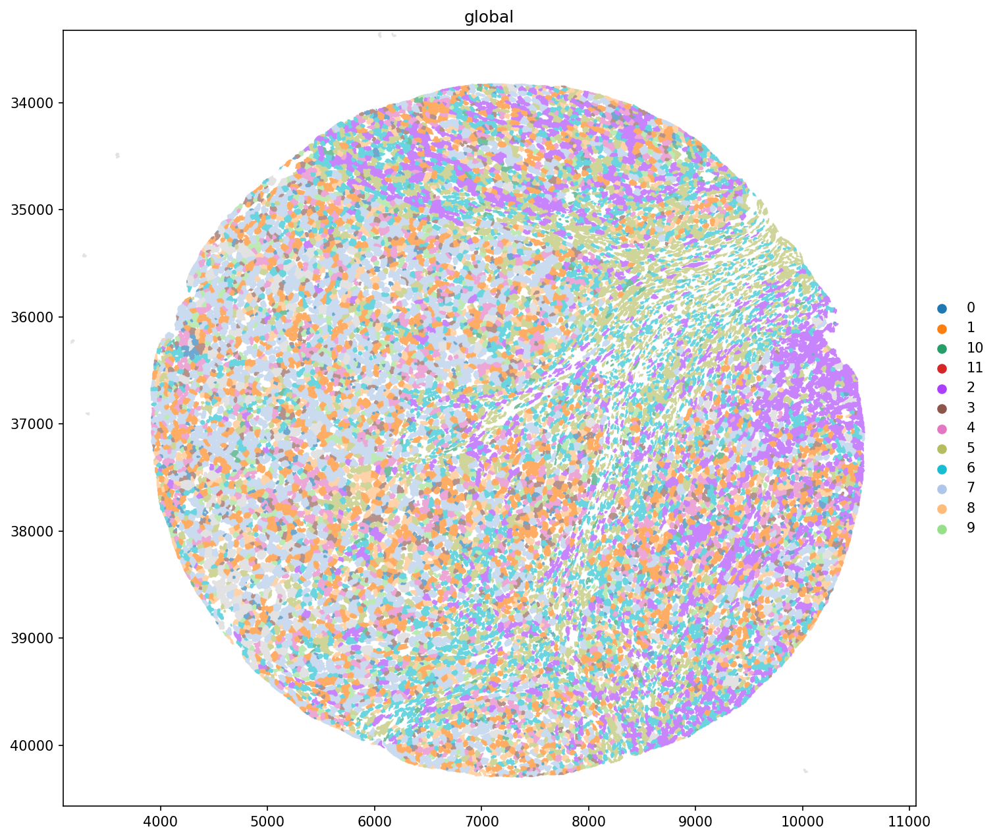

In [16]:
cats = sorted(andata.obs["stlieden_ratio1p5_r13"].astype(str).unique(), key=lambda x: int(x) if x.isdigit() else x)
palette_r13 = dict(zip(cats, sns.color_palette("tab20", n_colors=len(cats)).as_hex()))

sdata_obj.plot_punch(
    colname="stlieden_ratio1p5_r13",
    colname_map=map_spatialleiden_r13,
    palette=palette_r13,
    dpi=150,
)

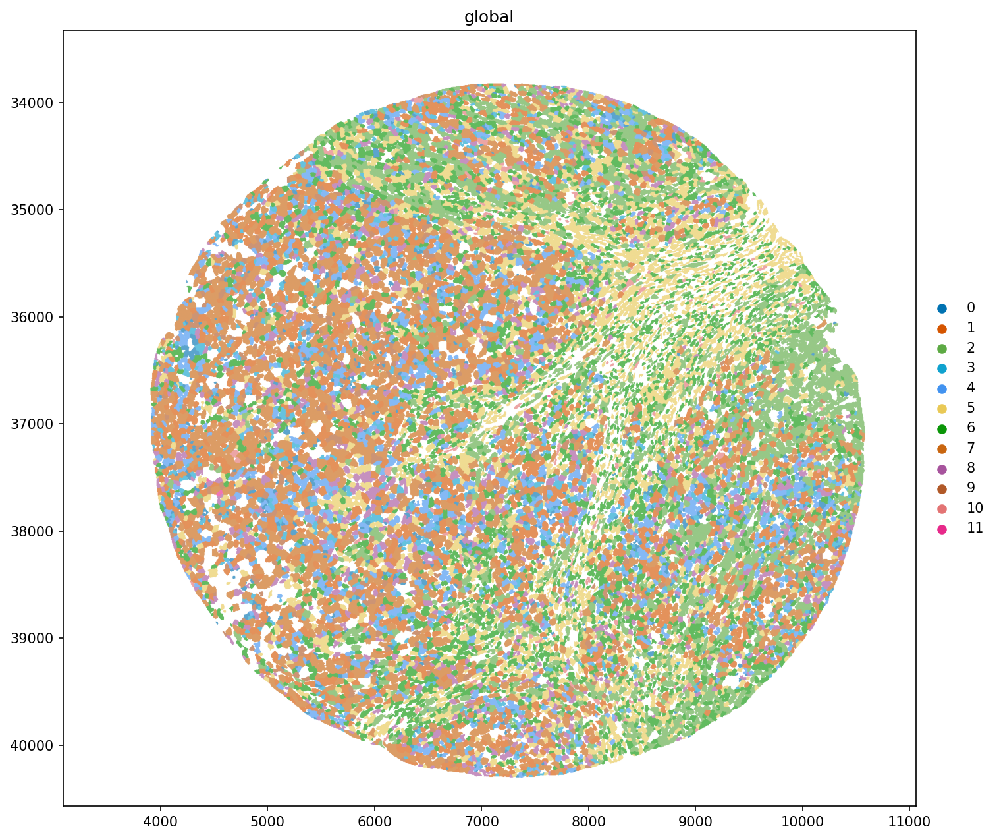

In [22]:
cluster_order_r13 = sorted(
    andata.obs["stlieden_ratio1p5_r13"].astype(str).unique(),
    key=lambda x: int(x) if x.isdigit() else x,
)

palette_r13_dict = {
    "0": "#0072B2",
    "1": "#D55500",
    "2": "#5DAA44",
    "3": "#10A2CF",
    "4": "#4293F0",
    "5": "#E9C956",
    "6": "#0B9608",
    "7": "#C96610",
    "8": "#A7549D",
    "9": "#B15928",
    "10": "#E37474",
    "11": "#E7298A",
    "12": "#B80FBB",
}

palette_r13 = [palette_r13_dict[x] for x in cluster_order_r13]

sdata_obj.sdata_crop["table"].obs["stlieden_ratio1p5_r13"] = pd.Categorical(
    sdata_obj.sdata_crop["table"].obs["cell_id"].map(map_spatialleiden_r13).astype(str),
    categories=cluster_order_r13,
    ordered=True,
)

sdata_obj.sdata_crop.pl.render_labels(
    "cell_labels",
    color="stlieden_ratio1p5_r13",
    groups=cluster_order_r13,
    palette=palette_r13,
).pl.show(
    coordinate_systems="global",
    figsize=(10, 10),
    dpi=150,
    na_in_legend=False,
)

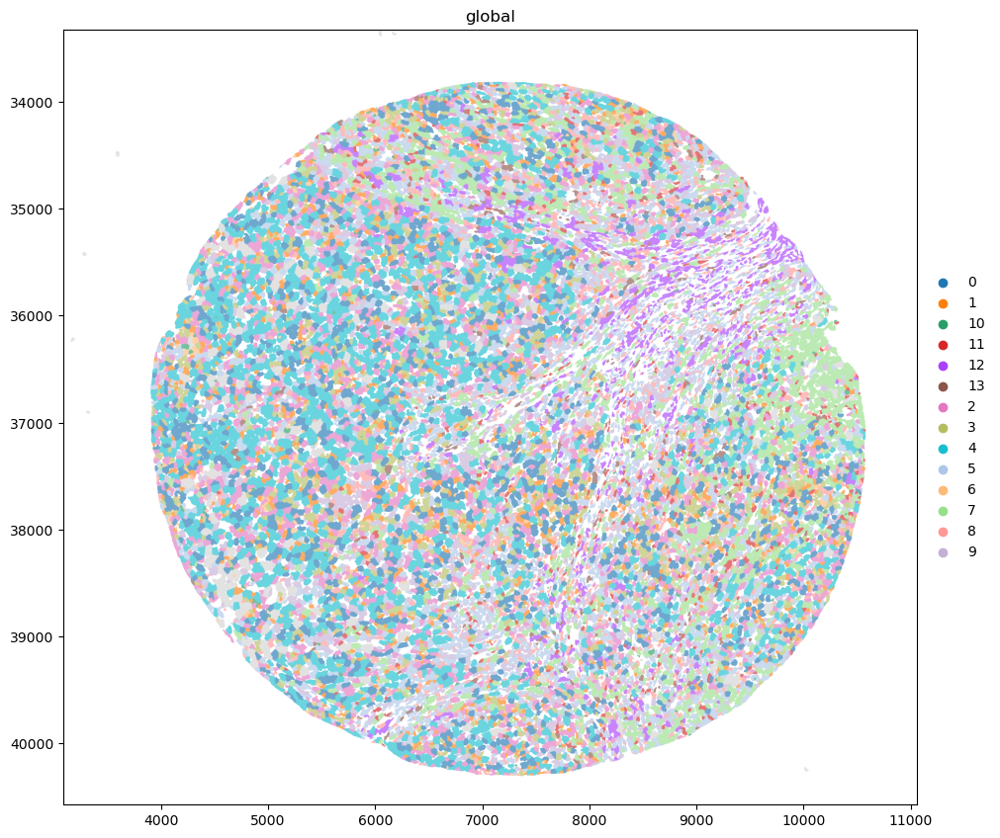

In [12]:
sdata_obj.plot_punch(colname= 'stlieden_ratio1p5_r13',colname_map = map_spatialleiden_r8)

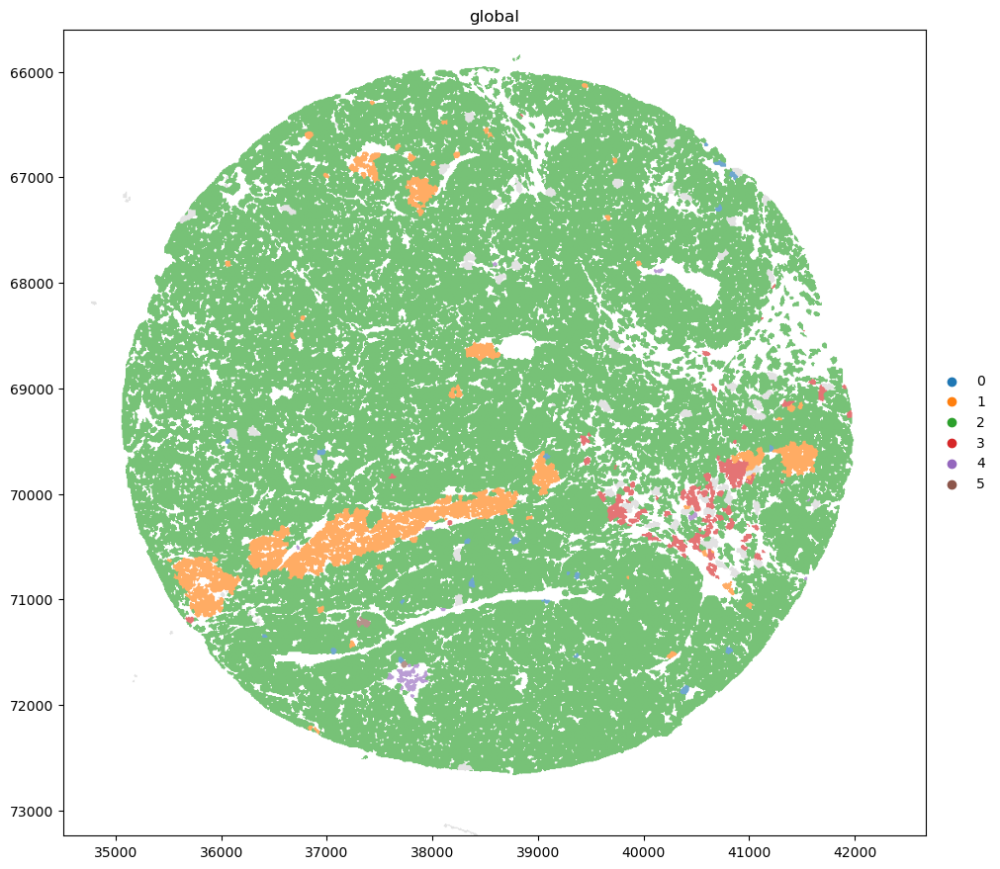

In [12]:
sdata_obj.plot_punch(colname= 'spatialleiden_weighted_1',colname_map = map_spatialleiden_07_low)

# Compute top 50 gene pair cluster

In [5]:
sc.tl.rank_genes_groups(andata, groupby='stlieden_ratio1p5_r13', method="wilcoxon",n_genes = 50,layer='log')
marks = sc.get.rank_genes_groups_df(andata, group = None)

In [6]:
pathout = '/data/kanferg/Sptial_Omics/projects/NguyenLab/neuroblastoma/tables'
marks.to_csv(os.path.join(pathout,f'NB_clusters_top50_v2.csv'))

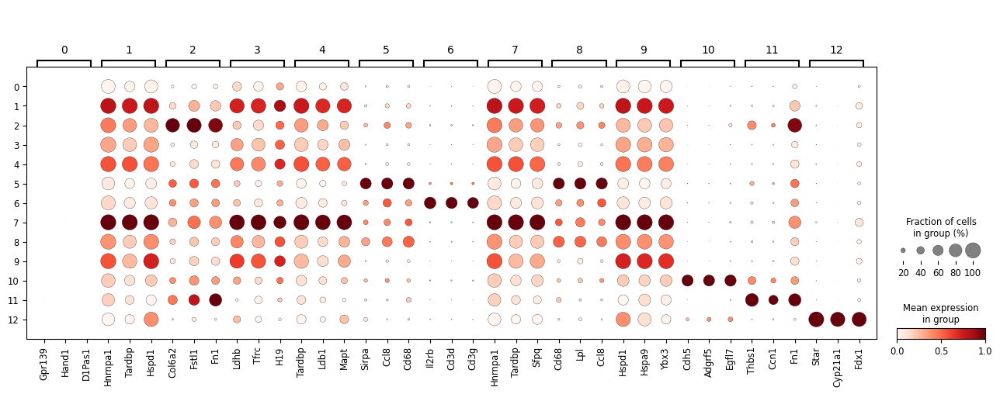

In [9]:
cluster_col = "stlieden_ratio1p5_r13"
cluster_order = [str(i) for i in range(len(andata.obs[cluster_col].cat.codes.unique()))]

andata.obs[cluster_col] = andata.obs[cluster_col].astype(str)
andata.obs[cluster_col] = pd.Categorical(
    andata.obs[cluster_col],
    categories=cluster_order,
    ordered=True,
)

andata_plot = andata[andata.obs[cluster_col].isin(cluster_order)].copy()

marks["group"] = marks["group"].astype(str)

marker_genes = {}
for cluster in cluster_order:
    genes = (
        marks[marks["group"] == cluster]
        .sort_values("scores", ascending=False)
        .head(3)["names"]
        .tolist()
    )
    marker_genes[cluster] = genes

sc.pl.dotplot(
    andata_plot,
    marker_genes,
    groupby=cluster_col,
    categories_order=cluster_order,
    standard_scale="var",
    mean_only_expressed=True,
    layer="log",
)